# IIT Guwahati — PRML Facial Expression Recognition
## CNN versus AC-GAN: per-class 6/3/3 split, seed 42
**Ahmdullah · M.Tech, Signal Processing and Machine Learning · Electronics and Electrical Engineering**

This notebook implements the corrected request: shuffle each class's 12 images separately; select 6 for training, 3 for validation, 3 for test; then shuffle the three combined partitions separately. Original photographs and generated faces are not embedded.

## 1. Exact requested allocation
| Class | Train | Validation | Test |
|---|---:|---:|---:|
| Happiness | 6 | 3 | 3 |
| Sadness | 6 | 3 | 3 |
| Fear | 6 | 3 | 3 |
| Neutral | 6 | 3 | 3 |
| **Total** | **24** | **12** | **12** |

This is **50%/25%/25%**, exactly the corrected 6/3/3 instruction. Each class is shuffled before allocation. Combined train, validation and test image orders are then shuffled independently. Seed 42 controls every stream. There is no image overlap, but people can appear in more than one partition. Therefore this is image-level evaluation, not unseen-subject evaluation. The earlier subject-independent studies remain separate baselines.

## 2. Environment
Run this notebook from the downloaded project repository (or its `notebooks/` folder). A notebook downloaded alone requires the repository modules. Use Python **3.12**.

```bash
git clone https://github.com/Ahmdullah16/PRML-Assignment.git
cd PRML-Assignment
python -m pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r requirements-dev.txt
python -m pip install nbformat nbclient ipykernel
```
Training is CPU compatible. The public Streamlit app performs inference only; it never runs this training notebook at startup.

In [1]:
%matplotlib inline
import os, sys, json, hashlib, platform
from pathlib import Path
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'PRML-Assignment']
ROOT = next((p.resolve() for p in candidates if (p / 'prml/holdout.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the PRML-Assignment repository; see setup instructions above.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage
from prml import CLASSES, SIZE, LATENT
from prml.holdout import prepare_dataset, run_experiment, export_experiment, verify_checkpoints, SPLIT_NAMES
from prml.models import CNN, Generator, Discriminator
from prml.train import seed_everything, discriminator_loss, generator_loss
from prml.inference import load_checkpoint, predict
from scripts.report_holdout import build_reports
torch.set_num_threads(4)
seed_everything(42)
display(pd.DataFrame([{'Python': platform.python_version(), 'PyTorch': str(torch.__version__), 'NumPy': np.__version__, 'seed': 42, 'device': 'cpu'}]))

,Python,PyTorch,NumPy,seed,device
0,3.12.14,2.14.1+cpu,2.2.6,42,cpu


## 3. Private dataset ZIP
The default below is the exact local path provided for this assignment. Set `PRML_DATA_ZIP` for another machine. Extraction admits only recognized class images and rejects path traversal and duplicate archive members. Existing different files are never silently overwritten. The raw images stay in ignored `data/`.

In [2]:
DATA_ZIP = Path(os.environ.get('PRML_DATA_ZIP', r'C:\Users\DELL\Downloads\ML LAB MINI PROJECT\PRML\PRML-Assignment\data\raw\PRML Assignment Data.zip'))
DATA_DIR = ROOT / 'data/seed42_zip'
RUN_DIR = ROOT / 'results/runs/class_6_3_3_seed42'
PUBLIC_RESULTS = ROOT / 'results/class_6_3_3_seed42'
if not DATA_ZIP.is_file():
    raise FileNotFoundError('Private ZIP not found; edit DATA_ZIP or set PRML_DATA_ZIP.')
rows, parts, split_manifest = prepare_dataset(DATA_ZIP, DATA_DIR, seed=42, strategy='class_6_3_3')
print('Validated images:', len(rows), '| Subjects:', len({r['subject'] for r in rows}))
print('ZIP SHA256:', hashlib.sha256(DATA_ZIP.read_bytes()).hexdigest())
display(pd.DataFrame([{'label': i, 'expression': c, 'images': sum(r['class'] == c for r in rows)} for i, c in enumerate(CLASSES)]))

Validated images: 48 | Subjects: 6
ZIP SHA256: e9eb78dfe556e6720e4d1463a1c2eb981a81de3b1e38f939165ef5e7fea5cd9e


,label,expression,images
0,0,sadness,12
1,1,happiness,12
2,2,neutral,12
3,3,fear,12


## 4. Dataset audit
Every image is decoded and checked against filename/folder labels. Exact decoded duplicates fail validation. SHA256 records bind the input files. Perceptual hashes flag review candidates, not proof of duplicate identity. Previously reviewed cross-subject matches are accepted only if their file hashes match.

,original_dimensions,images
0,2835x3543,48


Near-duplicate candidates: 69
Cross-subject candidates: 7


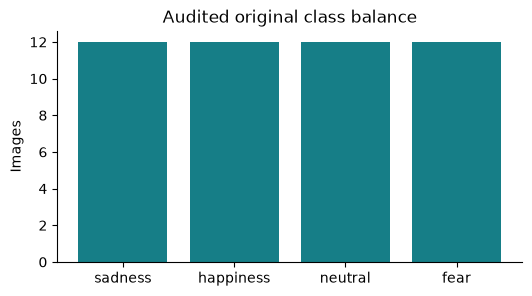

In [3]:
from prml.data import audit
audit_result = audit(rows)
display(pd.DataFrame([{'original_dimensions': k, 'images': v} for k, v in audit_result['dimensions'].items()]))
print('Near-duplicate candidates:', len(audit_result['near_duplicates']))
print('Cross-subject candidates:', sum(not p['same_subject'] for p in audit_result['near_duplicates']))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(CLASSES, [audit_result['counts'][c] for c in CLASSES], color='#167E87')
ax.set(title='Audited original class balance', ylabel='Images'); display(fig); plt.close(fig)

## 5. Shuffle each class, split 6/3/3, then mix each partition
`SeedSequence(42)` spawns four independent RNG streams for the four classes and three more streams for the combined partitions. The exact per-class shuffled order, final partition order and subject overlap audit are saved. Training batches additionally reshuffle each epoch. Validation/test images receive no random augmentation.

In [4]:
display(pd.DataFrame(split_manifest['per_class_shuffled_order']))
display(pd.DataFrame([{'partition': name, 'images': p['images'], 'share': p['actual_ratio'], **p['class_counts']}
                      for name, p in split_manifest['partitions'].items()]))
image_sets = [{r['filename'] for r in parts[name]} for name in SPLIT_NAMES]
assert not (image_sets[0] & image_sets[1] or image_sets[0] & image_sets[2] or image_sets[1] & image_sets[2])
assert len(set.union(*image_sets)) == 48
for name, count in zip(SPLIT_NAMES, [6, 3, 3]):
    assert all(sum(r['class'] == cls for r in parts[name]) == count for cls in CLASSES)
print('No repeated images across splits; exact 6/3/3 per class verified.')
print('Subject overlap audit:', split_manifest['subject_overlap'])

,sadness,happiness,neutral,fear
0,116_m_m_s_b.jpg,066_y_m_h_a.jpg,168_m_f_n_b.jpg,066_y_m_f_b.jpg
1,079_o_f_s_a.jpg,140_y_f_h_a.jpg,066_y_m_n_b.jpg,116_m_m_f_a.jpg
2,140_y_f_s_b.jpg,116_m_m_h_a.jpg,004_o_m_n_b.jpg,079_o_f_f_a.jpg
3,066_y_m_s_a.jpg,140_y_f_h_b.jpg,168_m_f_n_a.jpg,066_y_m_f_a.jpg
4,004_o_m_s_b.jpg,004_o_m_h_b.jpg,140_y_f_n_b.jpg,168_m_f_f_b.jpg
5,079_o_f_s_b.jpg,004_o_m_h_a.jpg,079_o_f_n_b.jpg,140_y_f_f_b.jpg
6,004_o_m_s_a.jpg,079_o_f_h_a.jpg,066_y_m_n_a.jpg,116_m_m_f_b.jpg
7,066_y_m_s_b.jpg,066_y_m_h_b.jpg,140_y_f_n_a.jpg,079_o_f_f_b.jpg
8,168_m_f_s_b.jpg,168_m_f_h_b.jpg,116_m_m_n_b.jpg,004_o_m_f_a.jpg
9,168_m_f_s_a.jpg,168_m_f_h_a.jpg,004_o_m_n_a.jpg,004_o_m_f_b.jpg


,partition,images,share,sadness,happiness,fear,neutral
0,train,24,0.50,6,6,6,6
1,validation,12,0.25,3,3,3,3
2,test,12,0.25,3,3,3,3


No repeated images across splits; exact 6/3/3 per class verified.
Subject overlap audit: {'train_vs_validation': ['004', '066', '079', '116', '140', '168'], 'train_vs_test': ['004', '079', '116', '140', '168'], 'validation_vs_test': ['004', '079', '116', '140', '168']}


## 6. Preprocessing and CNN
EXIF orientation → RGB → bilinear 64×64 resize → pixels in [−1,1]. The checkpoint-compatible CNN has conv/BN/ReLU/max-pool blocks at 16,32,64 channels; a 4096→64→4 dense head; dropout 0.3. The last layer emits logits; softmax is used for inference.

$$Y_{i,j,k}=\sum_{m,n,c} W_{m,n,c,k}X_{i+m,j+n,c}+b_k$$

$$p(y=k|x)=\frac{e^{z_k}}{\sum_{j=1}^{4}e^{z_j}},\qquad L_{CNN}=-\log p(y|x).$$

In [5]:
cnn = CNN()
discriminator = Discriminator()
generator = Generator()
display(pd.DataFrame([{'network': name, 'parameters': sum(p.numel() for p in net.parameters())}
                      for name, net in [('CNN', cnn), ('Discriminator', discriminator), ('Generator', generator)]]))
x = torch.zeros(2, 3, SIZE, SIZE)
assert cnn(x).shape == (2, 4)
fake = generator(torch.randn(2, LATENT), torch.tensor([0, 3]))
source_logits, class_logits = discriminator(fake)
assert fake.shape == (2, 3, 64, 64)
assert source_logits.shape == (2,) and class_logits.shape == (2, 4)
print('CNN, generator and discriminator tensor dimensions verified.')
del cnn, discriminator, generator, fake

,network,parameters
0,CNN,286276
1,Discriminator,710629
2,Generator,1022179


CNN, generator and discriminator tensor dimensions verified.


## 7. AC-GAN objective and correct gradient flow
The class-conditioned generator takes Gaussian noise and a label embedding. The discriminator emits source and expression logits; **its expression head performs classification**.

$$L_D=BCE(D_s(x),1)+BCE(D_s(G(z,c)),0)+CE(D_c(x),c)+CE(D_c(G(z,c)),c)$$

$$L_G=BCE(D_s(G(z,c)),1)+CE(D_c(G(z,c)),c).$$

All terms have unit weights. The generator source term is the explicitly non-saturating variant. Fake tensors detach for discriminator updates; discriminator weights freeze while retaining input gradients for generator updates. The generator checkpoint is saved at the same validation-selected epoch as the discriminator.

## 8. Fixed training and validation protocol
CNN: **25 epochs**. AC-GAN: **40 epochs**. Batch **8**, Adam lr **0.0002**. CNN betas=(0.9,0.999); GAN betas=(0.5,0.999). Seed **42** resets before each method. The best checkpoint minimizes validation classification cross-entropy. Test images do not enter training, augmentation, preprocessing fitting or model selection. No search is performed against test performance.

The next cell trains when no completed run exists. A matching completed run is replay-verified and reused, rather than silently retrained. To intentionally repeat training, use a new `RUN_DIR`; keep the split and budgets fixed.

In [6]:
reusing = (RUN_DIR / 'summary.json').exists()
summary = run_experiment(DATA_ZIP, DATA_DIR, RUN_DIR, ROOT / 'results/duplicate_review.json',
                         seed=42, cnn_epochs=25, gan_epochs=40, device='cpu', strategy='class_6_3_3')
print('Replayed and reused matching completed experiment.' if reusing else 'Executed new experiment and replay-verified saved checkpoints.')
display(pd.DataFrame([{'model': k, 'selected_epoch': v['best_epoch'], 'training_seconds': v['training_seconds']} for k, v in summary['models'].items()]))

Replayed and reused matching completed experiment.


,model,selected_epoch,training_seconds
0,cnn,25,1.957102
1,gan,2,9.840848


## 9. Separate final training report
Training metrics below are measured on unaugmented training images using the frozen selected checkpoint. They describe fit to seen subjects, not out-of-sample generalization.

In [7]:
metric_keys = ['loss', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
def partition_table(name):
    return pd.DataFrame({k.upper(): {m: v['partitions'][name][m] for m in metric_keys} for k, v in summary['models'].items()})
display(partition_table('train'))

,CNN,GAN
loss,0.405987,1.378439
accuracy,1.000000,0.500000
balanced_accuracy,1.000000,0.500000
macro_precision,1.000000,0.426511
macro_recall,1.000000,0.500000
macro_f1,1.000000,0.435425


## 10. Separate final validation report
These subjects select the checkpoint. Validation performance is selection-biased and must not be labeled test accuracy.

In [8]:
display(partition_table('validation'))

,CNN,GAN
loss,1.288441,1.386377
accuracy,0.416667,0.250000
balanced_accuracy,0.416667,0.250000
macro_precision,0.375000,0.121429
macro_recall,0.416667,0.250000
macro_f1,0.377778,0.162500


## 11. Separate frozen-model test report
The test contains **12 images, exactly 3 per class**. Each changed prediction moves accuracy by **8.33 percentage points**. No test image enters training, augmentation or checkpoint selection. However, shared subject identities and similar a/b photographs mean the scores cannot establish unseen-person recognition. The test set does not choose the seed, epoch budget, learning rate or public model.

In [9]:
display(partition_table('test'))
display(pd.DataFrame([{'model': kind.upper(), 'class': cls, **{m: model['partitions']['test'][m + '_by_class'][cls] for m in ['precision', 'recall', 'f1']}}
                      for kind, model in summary['models'].items() for cls in CLASSES]))

,CNN,GAN
loss,1.264922,1.390512
accuracy,0.416667,0.250000
balanced_accuracy,0.416667,0.250000
macro_precision,0.541667,0.166667
macro_recall,0.416667,0.250000
macro_f1,0.419444,0.194444


,model,class,precision,recall,f1
0,CNN,sadness,1.000000,0.333333,0.500000
1,CNN,happiness,0.333333,0.333333,0.333333
2,CNN,neutral,0.333333,0.666667,0.444444
3,CNN,fear,0.500000,0.333333,0.400000
4,GAN,sadness,0.000000,0.000000,0.000000
5,GAN,happiness,0.333333,0.333333,0.333333
6,GAN,neutral,0.333333,0.666667,0.444444
7,GAN,fear,0.000000,0.000000,0.000000


## 12. Learning curves and confusion matrices
Validation CE selects the checkpoint. Loss magnitudes differ across objectives, so compare classification metrics rather than raw CNN/GAN losses.

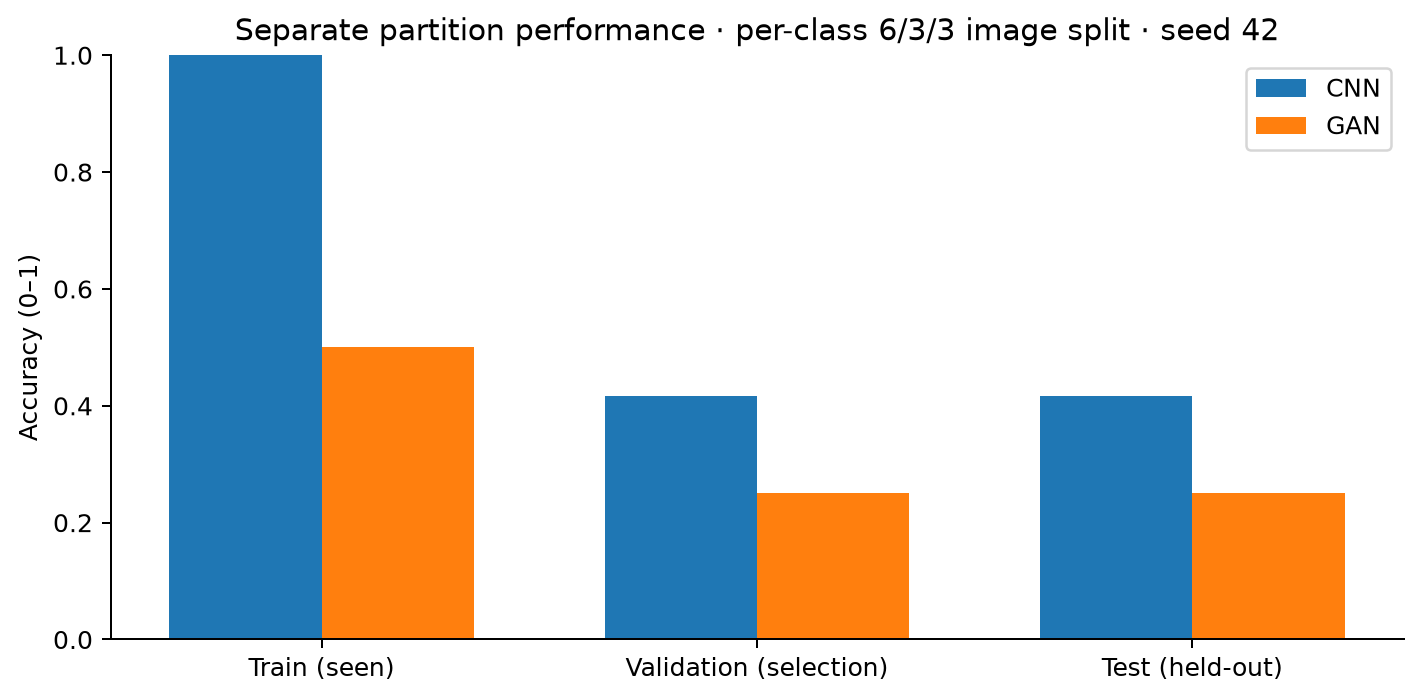

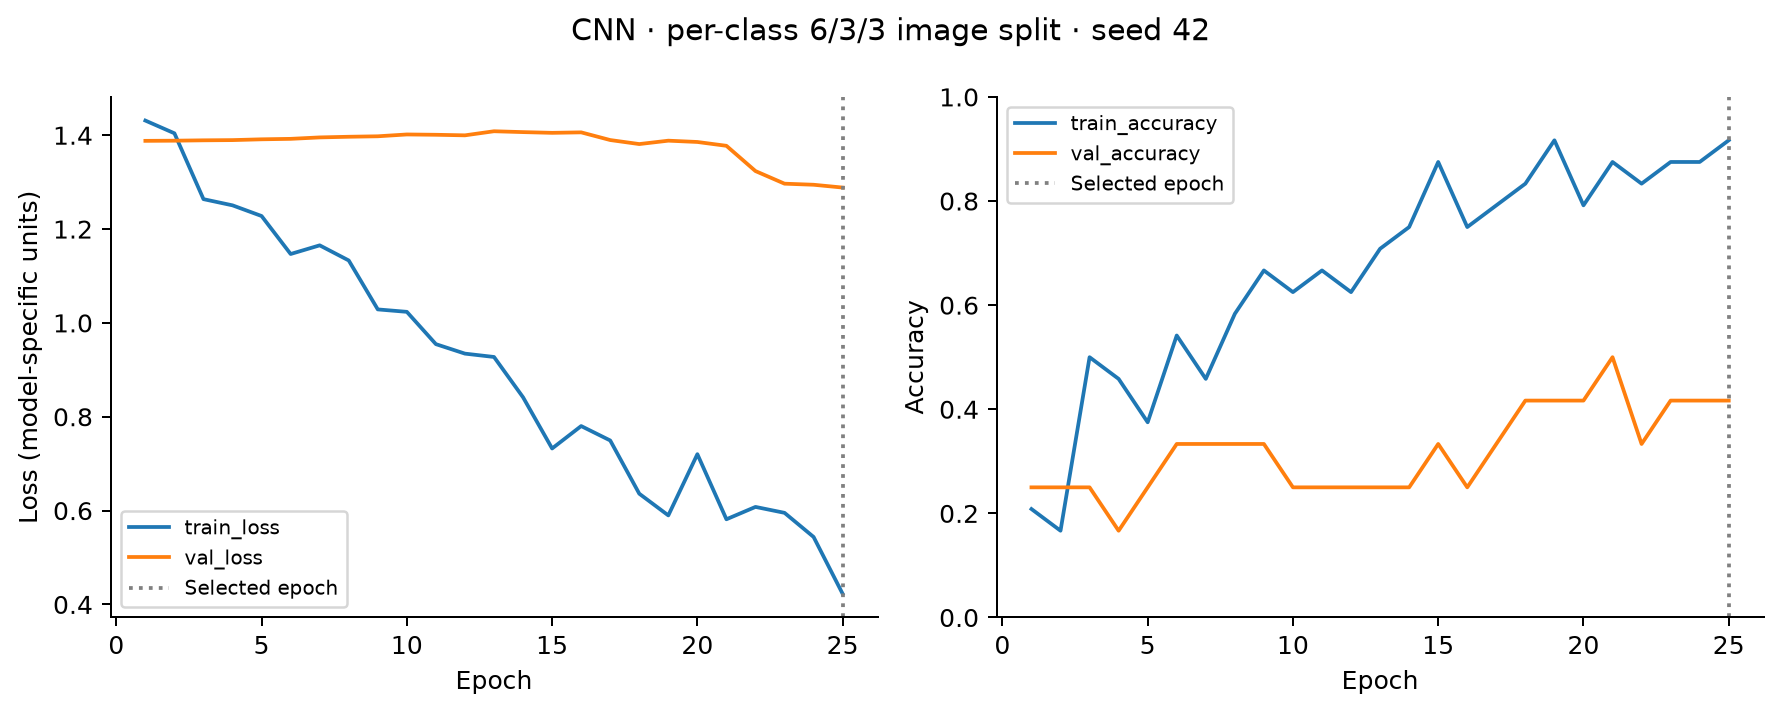

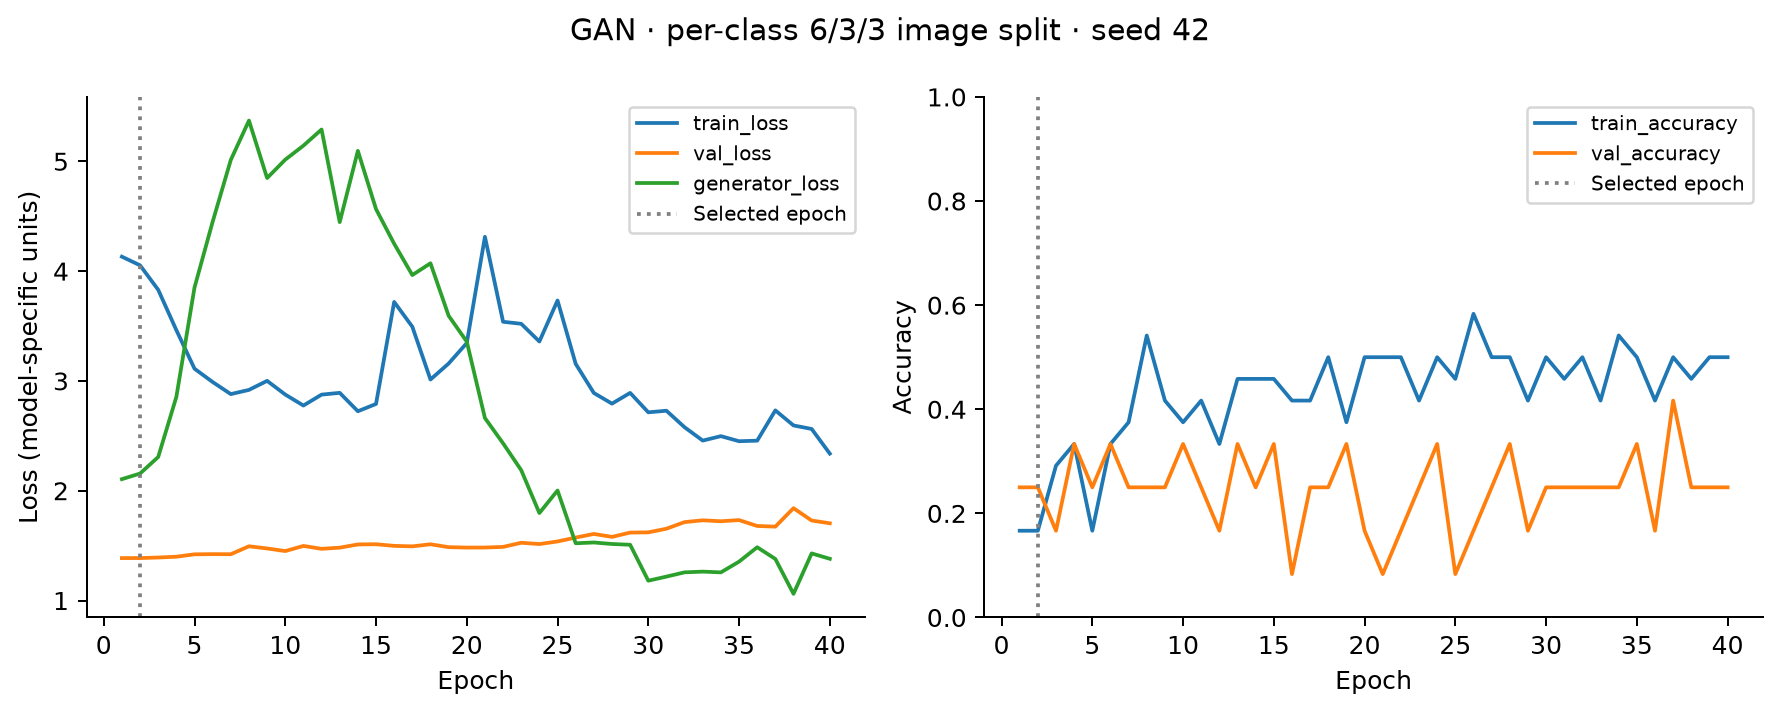

In [10]:
export_experiment(RUN_DIR, PUBLIC_RESULTS, ROOT / 'deployment')
build_reports(PUBLIC_RESULTS, ROOT / 'reports/class_6_3_3_seed42')
display(DisplayImage(filename=str(PUBLIC_RESULTS / 'figures/split_accuracy.png')))
for kind in ['cnn', 'gan']:
    display(DisplayImage(filename=str(PUBLIC_RESULTS / f'figures/{kind}_history.png')))

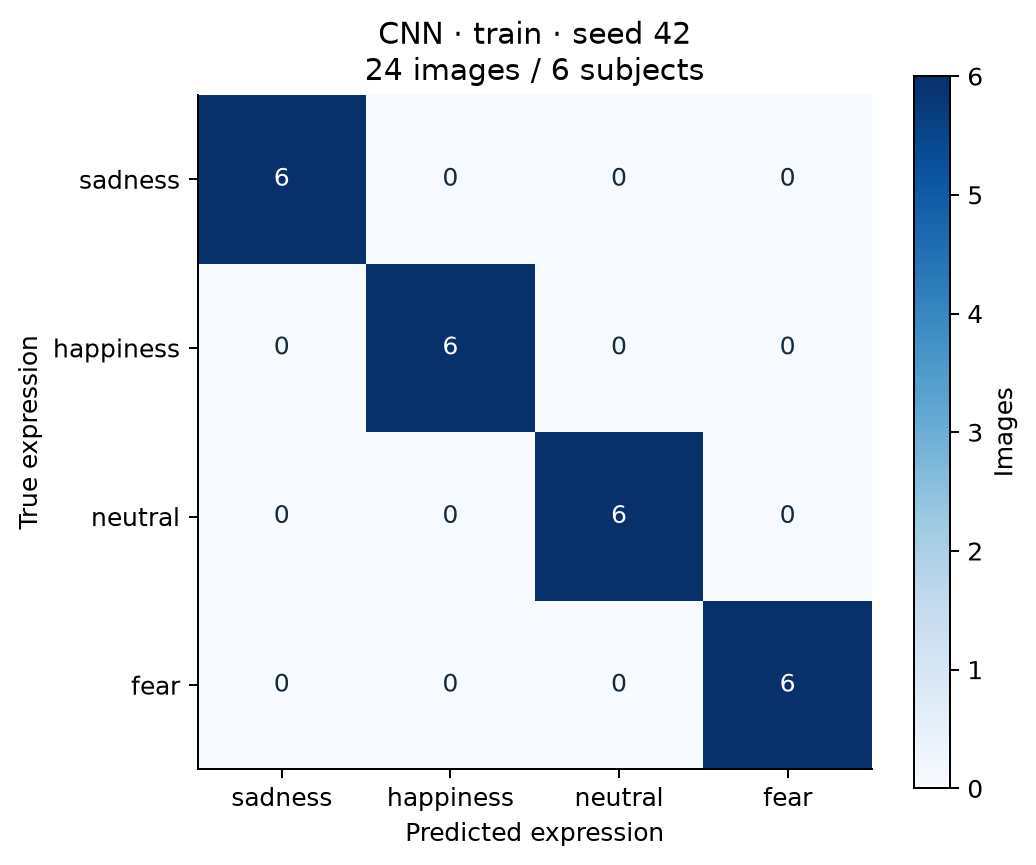

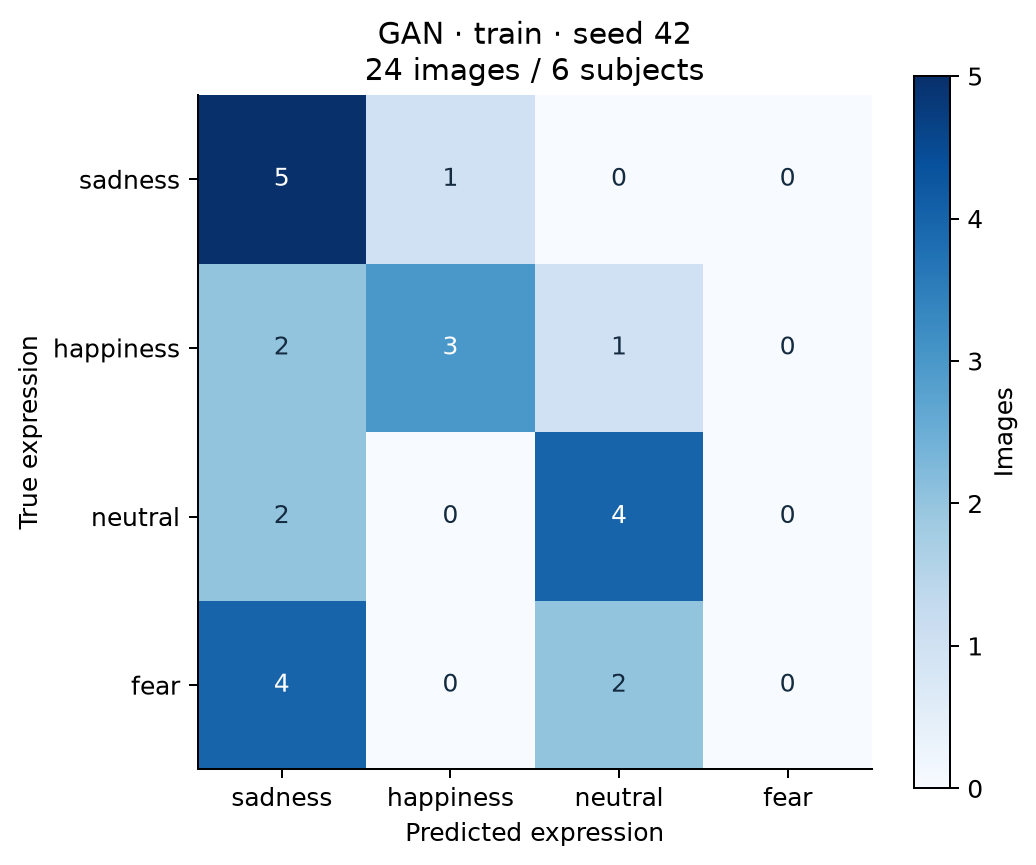

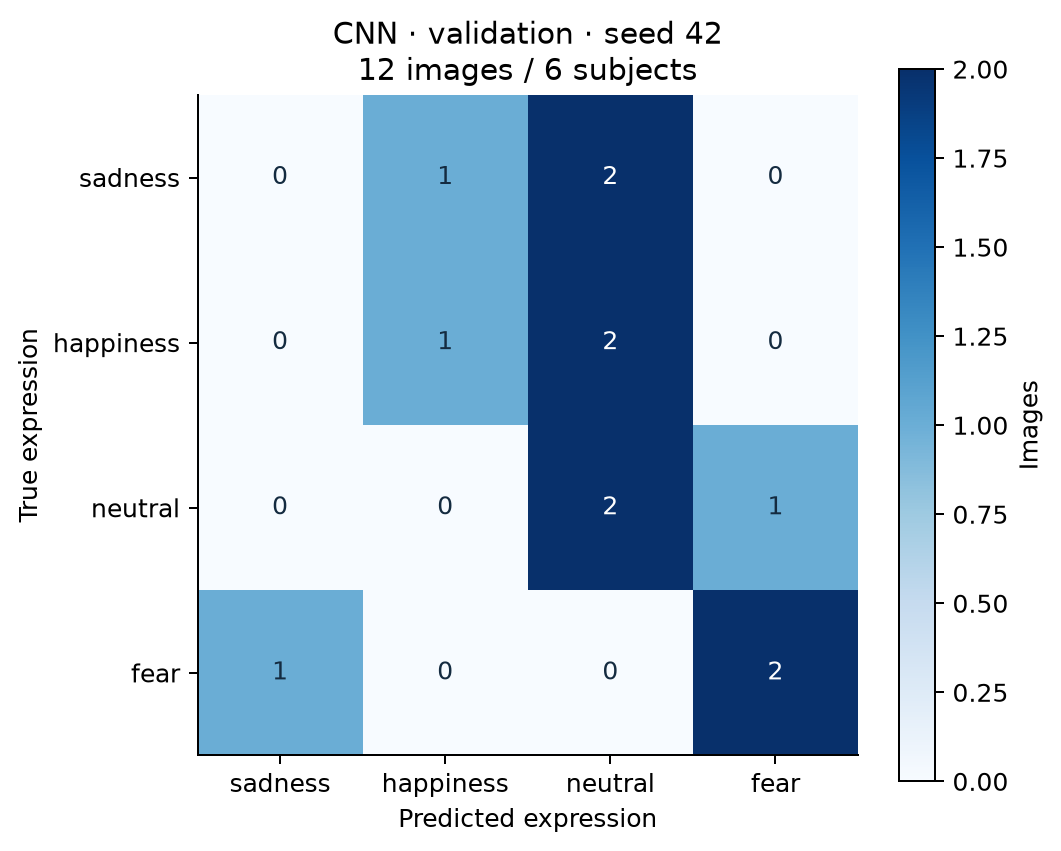

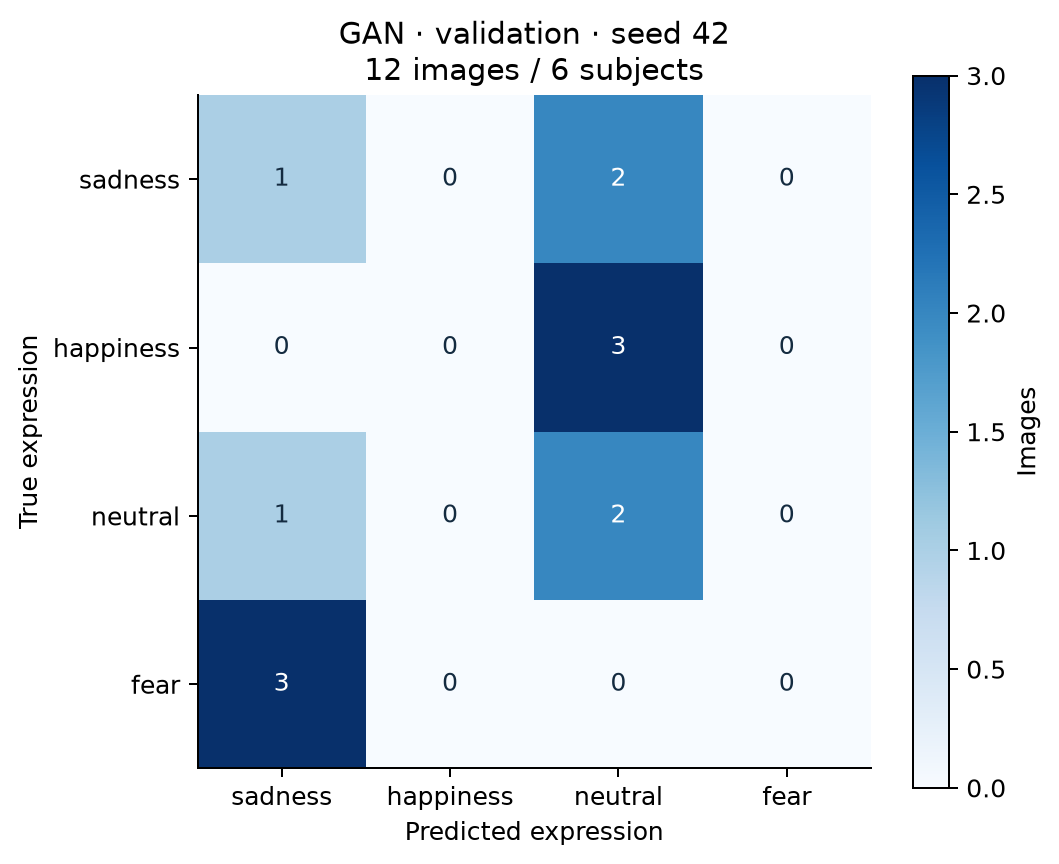

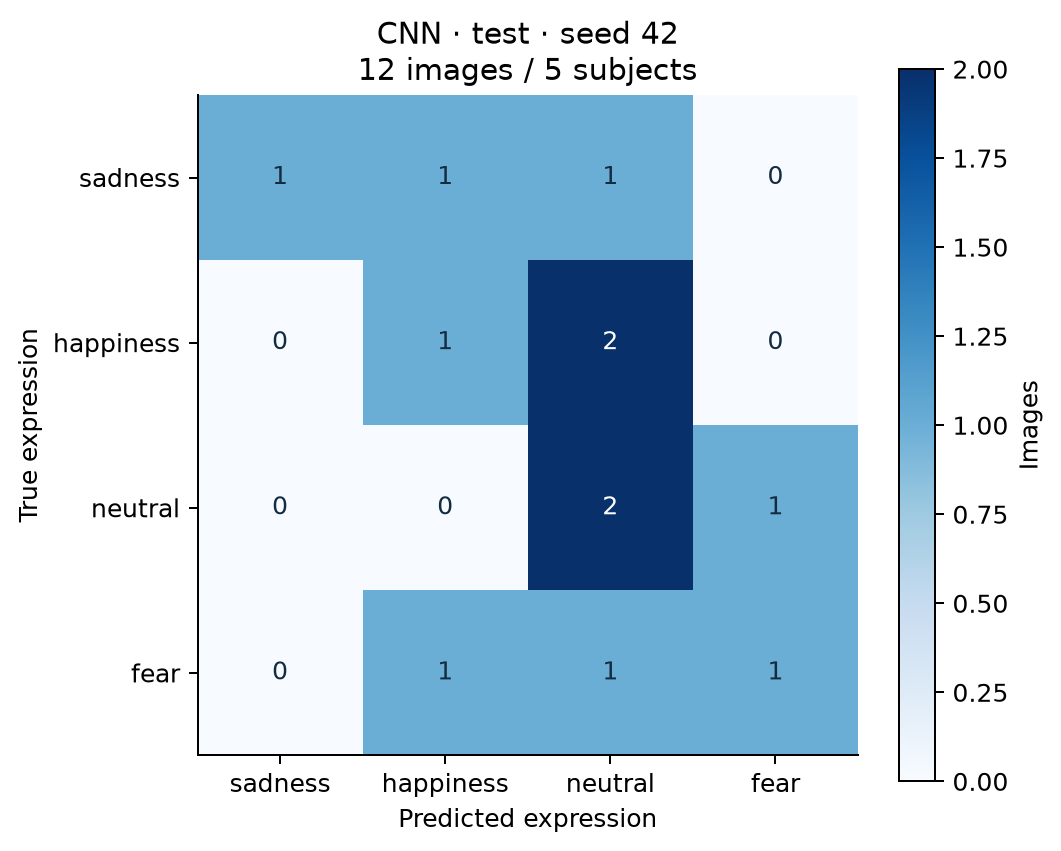

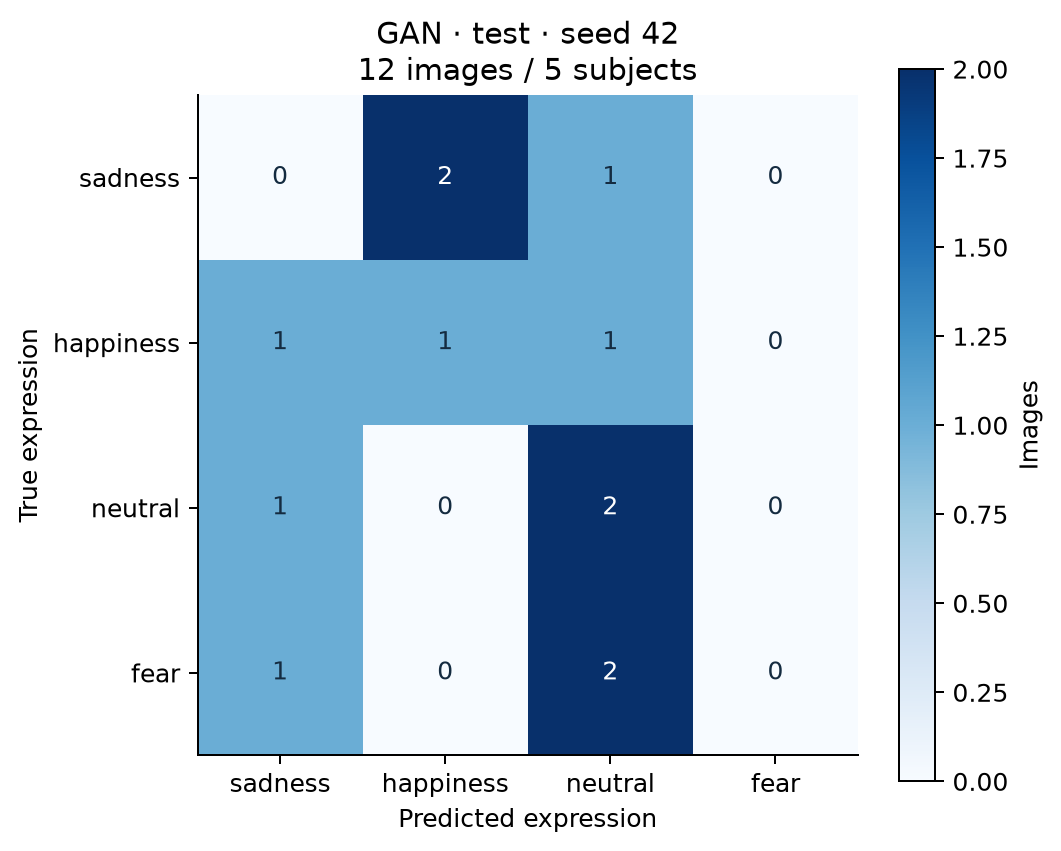

In [11]:
for split in SPLIT_NAMES:
    for kind in ['cnn', 'gan']:
        display(DisplayImage(filename=str(PUBLIC_RESULTS / f'figures/{split}_{kind}_confusion.png')))

## 13. Per-image prediction evidence and checkpoint replay
The following table contains codes and probabilities, not source photographs. Both saved classifiers are replayed on all three partitions. Replaying verifies saved outputs; it does not change the checkpoint or tune the model.

In [12]:
prediction_rows = []
for kind, model in summary['models'].items():
    for split, measured in model['partitions'].items():
        for p in measured['predictions']:
            prediction_rows.append({'model': kind, 'partition': split, **p})
prediction_frame = pd.DataFrame(prediction_rows)
display(prediction_frame[prediction_frame['partition'] == 'test'])
verify_checkpoints(parts, RUN_DIR, summary)
display(pd.DataFrame(json.loads((RUN_DIR / 'verification.json').read_text())['checks']))

,model,partition,filename,subject,true,predicted,probabilities
36,cnn,test,116_m_m_n_a.jpg,116,neutral,fear,"[0.30349719524383545, 0.15836620330810547, 0.2..."
37,cnn,test,140_y_f_f_a.jpg,140,fear,fear,"[0.09717822819948196, 0.10643820464611053, 0.0..."
38,cnn,test,004_o_m_n_a.jpg,004,neutral,neutral,"[0.19608446955680847, 0.23246364295482635, 0.4..."
39,cnn,test,079_o_f_n_a.jpg,079,neutral,neutral,"[0.18746304512023926, 0.054215967655181885, 0...."
40,cnn,test,079_o_f_h_b.jpg,079,happiness,neutral,"[0.24596790969371796, 0.16943955421447754, 0.3..."
41,cnn,test,168_m_f_f_a.jpg,168,fear,neutral,"[0.14265988767147064, 0.09932360798120499, 0.4..."
42,cnn,test,004_o_m_f_b.jpg,004,fear,happiness,"[0.2832571864128113, 0.480888307094574, 0.0844..."
43,cnn,test,116_m_m_s_a.jpg,116,sadness,sadness,"[0.3431070148944855, 0.2059086710214615, 0.121..."
44,cnn,test,168_m_f_h_a.jpg,168,happiness,neutral,"[0.10712345689535141, 0.15249979496002197, 0.5..."
45,cnn,test,116_m_m_h_b.jpg,116,happiness,happiness,"[0.2718486785888672, 0.3608264625072479, 0.107..."


,model,partition,images,replay_verified
0,cnn,train,24,True
1,cnn,validation,12,True
2,cnn,test,12,True
3,gan,train,24,True
4,gan,validation,12,True
5,gan,test,12,True


## 14. Inference example without publishing a face
Use a locally supplied authorized image for a real demonstration. This notebook uses an in-memory gray test image to verify the inference API only; the result is not a face-recognition claim. No image is sent to a server from this cell. Softmax scores are uncalibrated.

In [13]:
import io
from PIL import Image
buffer = io.BytesIO()
Image.new('RGB', (64, 64), (128, 128, 128)).save(buffer, format='PNG')
for kind in ['cnn', 'gan']:
    model, metadata = load_checkpoint(RUN_DIR / f'{kind}.pt')
    buffer.seek(0)
    scores = predict(model, kind, buffer)
    assert abs(sum(scores.values()) - 1) < 1e-6
    print(kind, scores)

cnn {'sadness': 0.29529550671577454, 'happiness': 0.19561664760112762, 'neutral': 0.28091320395469666, 'fear': 0.22817468643188477}
gan {'sadness': 0.25376561284065247, 'happiness': 0.2522546052932739, 'neutral': 0.2480078935623169, 'fear': 0.2459719330072403}


## 15. Interpretation and limitations
Training fit, validation selection and held-out-image test performance are reported separately. This exact class-stratified protocol allows subject overlap, which can make scores optimistic for unseen people. The earlier LOSO results provide the separate subject-independent comparison. Uniform guessing has expected accuracy 25%; a constant predictor also gets 25% on balanced classes. Only six people are represented, so the 48 images are not 48 independent people. No population confidence interval or universal CNN-versus-GAN conclusion is claimed. Outputs describe apparent expression categories, not actual emotions or mental state. A larger licensed dataset, external subjects, multiple seeds and calibration remain future work.

## 16. Deliverables and deployment
Separate reports are in `reports/class_6_3_3_seed42/`; split records, probabilities, histories and statistical figures are in `results/class_6_3_3_seed42/`. Only the two validation-selected classifiers are packaged for the authorized public prediction. The source ZIP, original photographs and generator remain private. The public app never trains at startup.

```bash
python -m pytest -q
python -m streamlit run app/streamlit_app.py
```

## 17. References
1. LeCun et al. (1998), [Gradient-Based Learning Applied to Document Recognition](https://bottou.org/papers/lecun-98h).
2. Goodfellow et al. (2014), [Generative Adversarial Networks](https://arxiv.org/abs/1406.2661).
3. Odena, Olah and Shlens (2017), [Conditional Image Synthesis With Auxiliary Classifier GANs](https://arxiv.org/abs/1610.09585).
4. [Project repository](https://github.com/Ahmdullah16/PRML-Assignment).